# Parte 1 – Recolección de noticias de El Comercio

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

| Configuración | Valor |
| :--- | :--- |
| Fecha de descarga | 2026-10-18 |
| Opción elegida | **B – El Comercio** |
| URL base | `https://elcomercio.pe` |
| Fuente de URLs | Sitemaps de noticias oficiales: `https://elcomercio.pe/sitemap/news/<seccion>/?outputType=xml` y `https://elcomercio.pe/sitemap/web/<seccion>/?outputType=xml` |
| Secciones consultadas | `politica`, `economia`, `deporte-total`, `tecnologia` |
| Categorías finales | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |

**Decisiones de recolección y respeto al medio**

- Se revisó `https://elcomercio.pe/robots.txt`: los sitemaps están declarados públicamente en el propio archivo y no hay `Disallow` sobre `/sitemap/` ni sobre las notas (solo `/catalogo/`, `/buscar/` y el archivo histórico antiguo).
- El feed RSS clásico (`/arcio/rss/category/<seccion>/`) responde con **301 Moved Permanently** y no devuelve ítems, así que se usaron los **sitemaps oficiales**, que son el canal que el medio publica para buscadores.
- Para cada nota se descarga la página una sola vez para obtener la **bajada** (`meta description`) y la fecha de publicación.
- `User-Agent` descriptivo, **pausa de 1.5 s** entre solicitudes y **máximo 1 reintento**.
- Toda la respuesta cruda se guarda en `datos/raw/` y, si ya existe, se reutiliza para no volver a consultar al medio.

In [1]:
import json, re, time
from pathlib import Path
from datetime import date

import requests
import pandas as pd
from bs4 import BeautifulSoup
import plotly.express as px
import plotly.io as pio

# Interactivo en VS Code/Jupyter + imagen PNG para que se vea en GitHub
pio.renderers.default = "plotly_mimetype+png"
pio.templates.default = "plotly_white"
COLORES = {"politica": "#4C78A8", "economia": "#F58518", "deportes": "#54A24B", "ciencia_tecnologia": "#B279A2"}
LAYOUT = dict(width=950, height=500, title_font_size=16)
pd.set_option("display.max_colwidth", 120)

BASE = "https://elcomercio.pe"
SECCIONES = ["politica", "economia", "deporte-total", "tecnologia"]
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; TareaUniversitaria-ClasificadorNoticias/1.0; curso Data Science Python; github.com/isabellaach)"}
PAUSA = 1.5          # segundos entre solicitudes
MAX_POR_SECCION = 120  # tope de notas por sección para no sobrecargar el sitio

RAW = Path("datos/raw"); RAW.mkdir(parents=True, exist_ok=True)
FECHA_DESCARGA = date.today().isoformat()
print("Fecha de descarga:", FECHA_DESCARGA)

Fecha de descarga: 2026-10-18


## 1. Extracción

### 1.1 `robots.txt` y función de descarga con pausa y 1 reintento

In [2]:
SESION = requests.Session()
SESION.headers.update(HEADERS)

def get(url, reintentos=1):
    """GET con pausa fija y como máximo 1 reintento."""
    for intento in range(reintentos + 1):
        time.sleep(PAUSA)
        try:
            r = SESION.get(url, timeout=(5, 10))  # (conexión, lectura)
            if r.status_code == 200:
                return r
            print(f"  [{r.status_code}] {url}")
        except requests.RequestException as e:
            print(f"  [error] {url}: {e}")
    return None

robots = get(f"{BASE}/robots.txt").text
(RAW / "robots_elcomercio.txt").write_text(robots, encoding="utf-8")
# Solo el bloque que aplica a todos los agentes (el resto bloquea scrapers maliciosos concretos)
bloque_general = robots.split("User-agent: *")[1].split("#")[0]
print("User-agent: *" + bloque_general)

User-agent: *
Disallow: /catalogo/
Disallow: /buscar/
Disallow: /archivo/todas/19*
Disallow: /archivo/todas/200*




In [3]:
# Comprobación documentada: el RSS clásico ya no está disponible
r = requests.get(f"{BASE}/arcio/rss/category/politica/", headers=HEADERS, timeout=20, allow_redirects=False)
print("RSS /arcio/rss/category/politica/ ->", r.status_code, r.reason)

RSS /arcio/rss/category/politica/ -> 301 Moved Permanently


### 1.2 Sitemaps por sección (respaldo crudo en `datos/raw/`)

In [4]:
NS = {"s": "http://www.sitemaps.org/schemas/sitemap/0.9",
      "news": "http://www.google.com/schemas/sitemap-news/0.9"}

registros = []
for sec in SECCIONES:
    for tipo in ["news", "web"]:
        archivo = RAW / f"sitemap_{tipo}_{sec}.xml"
        if not archivo.exists():
            r = get(f"{BASE}/sitemap/{tipo}/{sec}/?outputType=xml")
            if r is None:
                continue
            archivo.write_bytes(r.content)
        soup = BeautifulSoup(archivo.read_bytes(), "xml")
        for u in soup.find_all("url"):
            t = u.find("news:title") or u.find("title")
            f = u.find("news:publication_date") or u.find("lastmod")
            registros.append({
                "sitemap_seccion": sec, "sitemap_tipo": tipo,
                "url": u.find("loc").get_text(strip=True),
                "titular_sitemap": t.get_text(strip=True) if t else "",
                "fecha_sitemap": f.get_text(strip=True) if f else "",
            })

sitemap_df = pd.DataFrame(registros)
print("URLs en sitemaps:", len(sitemap_df))
sitemap_df.groupby(["sitemap_seccion", "sitemap_tipo"]).size().unstack()

URLs en sitemaps: 800


sitemap_tipo,news,web
sitemap_seccion,,
deporte-total,100,100
economia,100,100
politica,100,100
tecnologia,100,100


In [5]:
# Unión de sitemaps 'news' y 'web' por sección, sin repetir URL, hasta el tope por sección
candidatas = (sitemap_df.sort_values("sitemap_tipo")       # 'news' primero (trae titular)
              .drop_duplicates("url")
              .groupby("sitemap_seccion").head(MAX_POR_SECCION)
              .reset_index(drop=True))
print("URLs únicas a visitar:", len(candidatas))
candidatas["sitemap_seccion"].value_counts()

URLs únicas a visitar: 399


sitemap_seccion
politica         100
economia         100
deporte-total    100
tecnologia        99
Name: count, dtype: int64

### 1.3 Descarga de cada nota: titular, bajada y fecha

Se guarda un respaldo crudo (`datos/raw/articulos_raw.jsonl`) línea por línea, de modo que si la descarga se interrumpe se retoma donde quedó.

In [6]:
RAW_ART = RAW / "articulos_raw.jsonl"
ya = {}
if RAW_ART.exists():
    for linea in RAW_ART.read_text(encoding="utf-8").splitlines():
        d = json.loads(linea); ya[d["url"]] = d
print("Notas ya descargadas en respaldo:", len(ya))

def meta(soup, **attrs):
    tag = soup.find("meta", attrs=attrs)
    return tag["content"].strip() if tag and tag.get("content") else ""

pendientes = [u for u in candidatas["url"] if u not in ya]
print("Pendientes:", len(pendientes), f"(~{len(pendientes)*PAUSA/60:.1f} min)")

fallos_seguidos = 0
with RAW_ART.open("a", encoding="utf-8") as fh:
    for i, url in enumerate(pendientes, 1):
        r = get(url)
        d = {"url": url, "status": "ok" if r else "fallo"}
        if r:
            s = BeautifulSoup(r.text, "lxml")
            h1 = s.find("h1")
            d.update({
                "titular_html": h1.get_text(" ", strip=True) if h1 else meta(s, property="og:title"),
                "bajada": meta(s, name="description") or meta(s, property="og:description"),
                "fecha_html": meta(s, property="article:published_time"),
            })
        ya[url] = d
        fh.write(json.dumps(d, ensure_ascii=False) + "\n"); fh.flush()
        fallos_seguidos = 0 if r else fallos_seguidos + 1
        if fallos_seguidos >= 10:
            print("10 fallos seguidos: se detiene la descarga para no insistir sobre el sitio")
            break
        if i % 50 == 0:
            print(f"  {i}/{len(pendientes)} descargadas")

print("Total en respaldo:", len(ya))

Notas ya descargadas en respaldo: 399
Pendientes: 0 (~0.0 min)
Total en respaldo: 399


In [7]:
art = pd.DataFrame(ya.values())
crudo = candidatas.merge(art, on="url", how="left")

crudo["titular"] = crudo["titular_sitemap"].where(crudo["titular_sitemap"].str.len() > 0, crudo["titular_html"]).fillna("")
crudo["bajada"] = crudo["bajada"].fillna("")
crudo["medio"] = "El Comercio"
# Sección tal como figura en la URL de la nota, p.ej. 'economia/mercados' o 'deporte-total/futbol-peruano'
# (se quita el último tramo, que es el nombre de la nota)
crudo["seccion_original"] = (crudo["url"].str.replace(BASE + "/", "", regex=False).str.strip("/")
                             .str.split("/").str[:-1].str[:2].str.join("/"))
fechas = crudo["fecha_html"].fillna("").where(crudo["fecha_html"].fillna("").str.len() > 0, crudo["fecha_sitemap"])
crudo["fecha"] = pd.to_datetime(fechas, errors="coerce", utc=True).dt.tz_convert("America/Lima").dt.strftime("%Y-%m-%d")

crudo.to_csv(RAW / "noticias_crudas.csv", index=False)
print("Filas crudas:", crudo.shape)
print("Descargas fallidas:", (crudo["status"] != "ok").sum())
crudo[["titular", "bajada", "seccion_original", "fecha", "url"]].head()

Filas crudas: (399, 13)
Descargas fallidas: 0


,titular,bajada,seccion_original,fecha,url
0,Comisión de Constitución del Senado reanuda este lunes debate sobre el pedido de facultades legislativas,La Comisión de Constitución del Senado continuará este lunes con la sesión extraordinaria en la que se debatía la de...,politica,2026-10-18,https://elcomercio.pe/politica/facultades-delegadas-en-vivo-comision-de-constitucion-del-senado-predictamen-pedido-d...
1,Diputados: Informe recomienda suspender por 120 días a Julián Pérez Mallqui por agresión a su expareja,La situación del diputado Julián Pérez Mallqui (Juntos por el Perú) se complica. La Comisión de Ética Parlamentaria ...,politica,2026-10-18,https://elcomercio.pe/politica/diputados-informe-recomienda-suspender-por-120-dias-a-julian-perez-mallqui-por-agresi...
2,Campañas del “No a la Revocatoria” y Reelección Municipal: Caso contra Susana Villarán se encamina a los diez años s...,"El caso seguido contra la exalcaldesa de Lima, Susana Villarán, por la presunta recepción de dinero ilícito para sus...",politica,2026-10-18,https://elcomercio.pe/politica/susana-villaran-caso-contra-exalcaldesa-por-presuntas-irregularidades-en-las-campanas...
3,Álvaro Vargas Llosa: “EE.UU. nos está ayudando a recuperar la soberanía que las mafias ponen en peligro”,"Álvaro Vargas Llosa Asumirá el cargo el 16 de noviembre, pero en esta conversación adelanta lo que serán varias clav...",politica,2026-10-18,https://elcomercio.pe/politica/alvaro-vargas-llosa-eeuu-embajador-del-peru-en-estados-unidos-entrevista-noticia/
4,"El Senado también se la juega, una crónica de Fernando Vivas sobre la pugna por las facultades legislativas","Tras la agónica aprobación de facultades acotadas en Diputados, con Fuerza Popular apostando al todo o nada; en el s...",politica,2026-10-18,https://elcomercio.pe/politica/el-senado-tambien-se-la-juega-una-cronica-de-fernando-vivas-congreso-facultades-legis...


## 2. Limpieza y normalización

In [8]:
df = crudo.copy()
for c in ["titular", "bajada"]:
    df[c] = df[c].str.replace(r"\s+", " ", regex=True).str.strip()

descartes = []
def descartar(mask, motivo):
    global df
    descartes.append({"motivo": motivo, "n": int(mask.sum())})
    df = df[~mask]

descartar(df.duplicated("url"), "URL duplicada")
descartar(df["titular"].eq(""), "Titular vacío")
descartar(df.duplicated("titular"), "Titular duplicado (misma nota con otra URL)")
print("Filas tras duplicados/vacíos:", len(df))

Filas tras duplicados/vacíos: 399


### 2.1 Tabla de equivalencias `seccion_original` → categoría

El mapeo se hace por la **primera parte de la ruta** de la URL (la sección madre del diario). La sección `elecciones` se asigna a `politica`. Se descartan `opinion` (columnas de opinión, no un tema), `ecdata` (periodismo de datos con temas mezclados) y `ruedas-tuercas` (autos). Las subsecciones que no corresponden a ninguna de las 4 categorías (p. ej. notas de servicios o de otras secciones que aparecen en el sitemap) se descartan, sin crear una quinta categoría.

In [9]:
MAPEO_SECCION = {
    "politica": "politica",
    "elecciones": "politica",
    "economia": "economia",
    "deporte-total": "deportes",
    "tecnologia": "ciencia_tecnologia",
    "ciencias": "ciencia_tecnologia",
}
df["seccion_madre"] = df["seccion_original"].str.split("/").str[0]
df["etiqueta"] = df["seccion_madre"].map(MAPEO_SECCION)

tabla_mapeo = (df.groupby(["seccion_original", "etiqueta"], dropna=False).size()
                 .reset_index(name="n_noticias")
                 .sort_values(["etiqueta", "n_noticias"], ascending=[True, False]))
tabla_mapeo["etiqueta"] = tabla_mapeo["etiqueta"].fillna("— descartada —")
tabla_mapeo

,seccion_original,etiqueta,n_noticias
30,tecnologia/actualidad,ciencia_tecnologia,37
35,tecnologia/inteligencia-artificial,ciencia_tecnologia,19
32,tecnologia/ciencias,ciencia_tecnologia,10
31,tecnologia/ciberseguridad,ciencia_tecnologia,7
33,tecnologia/ecologia,ciencia_tecnologia,6
40,tecnologia/videojuegos,ciencia_tecnologia,5
36,tecnologia/moviles,ciencia_tecnologia,4
34,tecnologia/gadgets,ciencia_tecnologia,3
37,tecnologia/redes-sociales,ciencia_tecnologia,2
38,tecnologia/robotica,ciencia_tecnologia,1


In [10]:
no_mapeadas = df["etiqueta"].isna()
if no_mapeadas.any():
    print("Secciones sin categoría (se descartan):", df.loc[no_mapeadas, "seccion_original"].value_counts().to_dict())
descartar(no_mapeadas, "Sección fuera de las 4 categorías")

reporte_descartes = pd.DataFrame(descartes)
reporte_descartes.loc[len(reporte_descartes)] = ["TOTAL descartadas", reporte_descartes["n"].sum()]
print(f"Filas crudas: {len(crudo)}  ->  filas limpias: {len(df)}")
reporte_descartes

Secciones sin categoría (se descartan): {'opinion/columnistas': 6, 'ecdata': 4, 'ruedas-tuercas/automotriz': 2, 'bbc-news-mundo': 2, 'eldominical/ciencia': 1}
Filas crudas: 399  ->  filas limpias: 384


,motivo,n
0,URL duplicada,0
1,Titular vacío,0
2,Titular duplicado (misma nota con otra URL),0
3,Sección fuera de las 4 categorías,15
4,TOTAL descartadas,15


## 3. Análisis exploratorio (EDA)

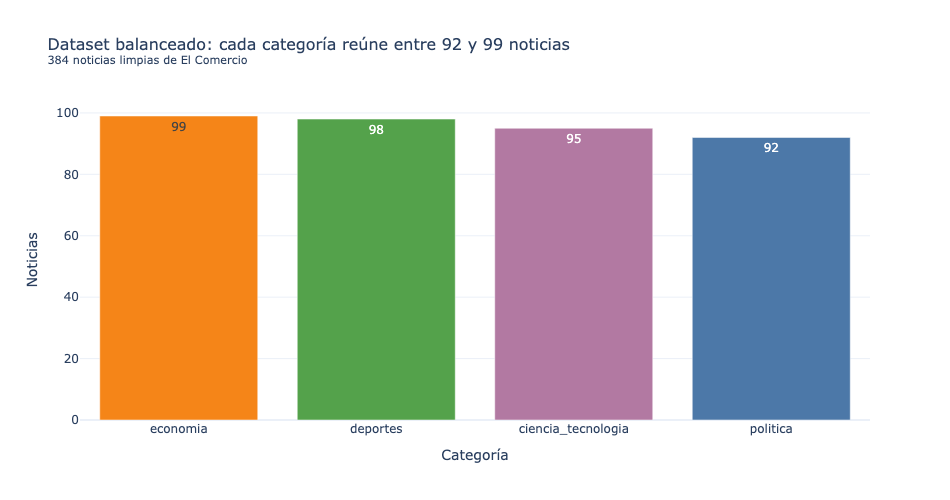

In [11]:
df["largo_titular"] = df["titular"].str.len()
conteo = df["etiqueta"].value_counts().rename_axis("categoria").reset_index(name="noticias")
mn, mx = conteo["noticias"].min(), conteo["noticias"].max()

fig = px.bar(conteo, x="categoria", y="noticias", color="categoria", text="noticias", color_discrete_map=COLORES,
             title=f"Dataset balanceado: cada categoría reúne entre {mn} y {mx} noticias<br><sup>{len(df)} noticias limpias de El Comercio</sup>")
fig.update_layout(showlegend=False, xaxis_title="Categoría", yaxis_title="Noticias", **LAYOUT)
fig.show()

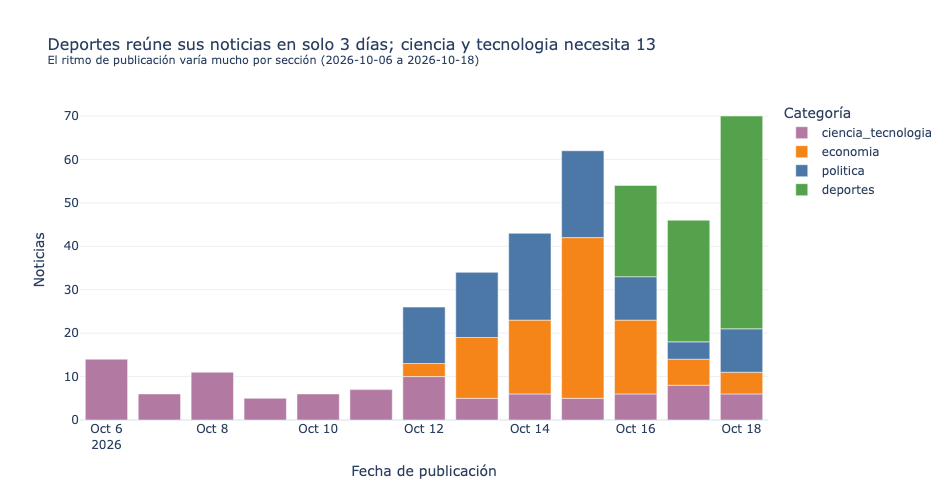

Rango de fechas: 2026-10-06 a 2026-10-18
Días cubiertos por categoría: {'ciencia_tecnologia': 13, 'deportes': 3, 'economia': 7, 'politica': 7}


In [12]:
por_fecha = df.groupby(["fecha", "etiqueta"]).size().reset_index(name="noticias")
dias = df.groupby("etiqueta")["fecha"].agg(lambda s: (pd.to_datetime(s.max()) - pd.to_datetime(s.min())).days + 1)
rapida, lenta = dias.idxmin(), dias.idxmax()

fig = px.bar(por_fecha, x="fecha", y="noticias", color="etiqueta", color_discrete_map=COLORES,
             title=(f"{rapida.replace('_', ' ').capitalize()} reúne sus noticias en solo {dias.min()} días; "
                    f"{lenta.replace('_', ' y ')} necesita {dias.max()}<br><sup>El ritmo de publicación varía mucho por sección "
                    f"({df['fecha'].min()} a {df['fecha'].max()})</sup>"))
fig.update_layout(xaxis_title="Fecha de publicación", yaxis_title="Noticias", legend_title="Categoría", **LAYOUT)
fig.show()
print("Rango de fechas:", df["fecha"].min(), "a", df["fecha"].max())
print("Días cubiertos por categoría:", dias.to_dict())

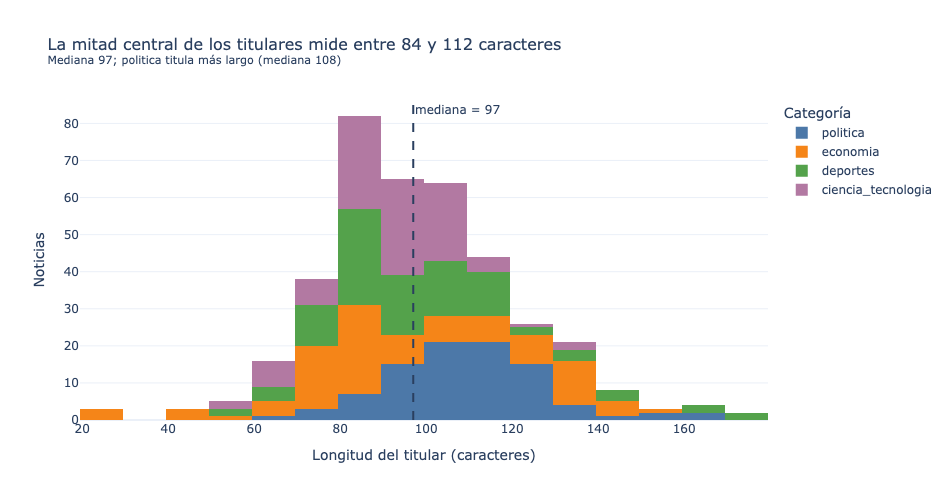

,mediana_caracteres
etiqueta,
economia,89.0
deportes,92.0
ciencia_tecnologia,93.0
politica,108.5


In [13]:
med = df["largo_titular"].median()
med_cat = df.groupby("etiqueta")["largo_titular"].median().sort_values()

fig = px.histogram(df, x="largo_titular", nbins=30, color="etiqueta", color_discrete_map=COLORES,
                   title=(f"La mitad central de los titulares mide entre {int(df['largo_titular'].quantile(.25))} y "
                          f"{int(df['largo_titular'].quantile(.75))} caracteres<br><sup>Mediana {med:.0f}; "
                          f"{med_cat.index[-1].replace('_', ' y ')} titula más largo (mediana {med_cat.iloc[-1]:.0f})</sup>"))
fig.add_vline(x=med, line_dash="dash", annotation_text=f"mediana = {med:.0f}")
fig.update_layout(xaxis_title="Longitud del titular (caracteres)", yaxis_title="Noticias", legend_title="Categoría", **LAYOUT)
fig.show()
med_cat.rename("mediana_caracteres").to_frame()

## 4. Validación: titulares más largos y más cortos

In [14]:
cols = ["titular", "largo_titular", "etiqueta"]
print("5 titulares MÁS LARGOS")
display(df.nlargest(5, "largo_titular")[cols])
print("5 titulares MÁS CORTOS")
display(df.nsmallest(5, "largo_titular")[cols])
print(f"Mínimo {df['largo_titular'].min()} y máximo {df['largo_titular'].max()} caracteres: "
      "coinciden con los extremos del histograma.")

5 titulares MÁS LARGOS


,titular,largo_titular,etiqueta
224,"“El jugador peruano tiene un déficit grande en nutrición y táctica que resuelve a los 20 años, eso en Argentina es a...",178,deportes
225,El furioso “Que se dedique a administrar” de Guede a Franco Velazco y un Quevedo que reconquistó a Comando Sur: Lo q...,171,deportes
277,“Creo que puedo llegar a un top 3 sin que nadie se quede botado”: Raúl ‘Mono’ Orlandini le responde a El Comercio so...,167,deportes
64,"Keiko Fujimori sobre Álvaro Vargas Llosa: “Confío en que su trayectoria, experiencia y compromiso contribuirán a for...",166,politica
60,"Juan Sheput sobre eventual suspensión del viaje del papa León XIV al Perú: “Es posible, pero todavía no está la pala...",160,politica


5 titulares MÁS CORTOS


,titular,largo_titular,etiqueta
165,Invocación por el Perú,22,economia
108,AlaCena no tiene precio,23,economia
127,IA y Sandbox regulatorio,24,economia
179,La evolución de la confianza en los pagos,41,economia
109,Premio Nobel de Economía: la macro es micro,43,economia


Mínimo 22 y máximo 178 caracteres: coinciden con los extremos del histograma.


**Lectura de la validación:** los titulares más largos son de deportes y política y suelen ser **citas textuales entre comillas** (entrevistas y declaraciones), lo que explica la cola derecha del histograma y la mediana más alta de política. Los más cortos son de economía y corresponden a **columnas o contenidos de marca** con títulos creativos (p. ej. *"Invocación por el Perú"*), que no mencionan el tema de forma explícita: serán casos difíciles para el clasificador.

## 5. Exportación de `datos/noticias.csv`

In [15]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
noticias = df[COLUMNAS].reset_index(drop=True)
noticias.to_csv("datos/noticias.csv", index=False, encoding="utf-8")

print("df.shape:", noticias.shape)
print("Bajadas vacías:", (noticias["bajada"] == "").sum())
noticias.head()

df.shape: (384, 7)
Bajadas vacías: 0


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Comisión de Constitución del Senado reanuda este lunes debate sobre el pedido de facultades legislativas,La Comisión de Constitución del Senado continuará este lunes con la sesión extraordinaria en la que se debatía la de...,El Comercio,politica,https://elcomercio.pe/politica/facultades-delegadas-en-vivo-comision-de-constitucion-del-senado-predictamen-pedido-d...,2026-10-18,politica
1,Diputados: Informe recomienda suspender por 120 días a Julián Pérez Mallqui por agresión a su expareja,La situación del diputado Julián Pérez Mallqui (Juntos por el Perú) se complica. La Comisión de Ética Parlamentaria ...,El Comercio,politica,https://elcomercio.pe/politica/diputados-informe-recomienda-suspender-por-120-dias-a-julian-perez-mallqui-por-agresi...,2026-10-18,politica
2,Campañas del “No a la Revocatoria” y Reelección Municipal: Caso contra Susana Villarán se encamina a los diez años s...,"El caso seguido contra la exalcaldesa de Lima, Susana Villarán, por la presunta recepción de dinero ilícito para sus...",El Comercio,politica,https://elcomercio.pe/politica/susana-villaran-caso-contra-exalcaldesa-por-presuntas-irregularidades-en-las-campanas...,2026-10-18,politica
3,Álvaro Vargas Llosa: “EE.UU. nos está ayudando a recuperar la soberanía que las mafias ponen en peligro”,"Álvaro Vargas Llosa Asumirá el cargo el 16 de noviembre, pero en esta conversación adelanta lo que serán varias clav...",El Comercio,politica,https://elcomercio.pe/politica/alvaro-vargas-llosa-eeuu-embajador-del-peru-en-estados-unidos-entrevista-noticia/,2026-10-18,politica
4,"El Senado también se la juega, una crónica de Fernando Vivas sobre la pugna por las facultades legislativas","Tras la agónica aprobación de facultades acotadas en Diputados, con Fuerza Popular apostando al todo o nada; en el s...",El Comercio,politica,https://elcomercio.pe/politica/el-senado-tambien-se-la-juega-una-cronica-de-fernando-vivas-congreso-facultades-legis...,2026-10-18,politica


## Conclusiones de la Parte 1

- Se recolectaron noticias reales de El Comercio desde sus sitemaps oficiales (el RSS clásico ya no responde), respetando `robots.txt`, con pausas de 1.5 s y un único reintento.
- Cada fila tiene titular, bajada, sección original, URL funcional, fecha y una etiqueta estandarizada entre las 4 categorías oficiales.
- Los descartes (duplicados, vacíos y secciones fuera de las 4 categorías) quedan reportados arriba.
- El dataset queda listo para el etiquetado con LLM y el modelado de la Parte 2.